# Manufacturing (VisA pcb1): data prep

**Phase:** 1 | **Input:** raw VisA `pcb1` (csv, images, masks) | **Output:** `bench/` (git-ignored)

Builds the one dataset every model uses, applying the fixes found in `01_eda`:

| EDA finding | Fix here |
|---|---|
| Orientation leaks the label | every used `rotated_180` image is turned upright with its mask; boxes are derived after the rotation |
| Small defects unevenly split | the defect split is stratified by "has a small box" |
| Defects visible without color | every image is written twice: `gray/` (first training run) and `color/` (second run, VLMs) |
| Board covers only about 2/3 of the frame | every image gets the same crop rule: board + small margin + room for the pins, then resized to 1024 x 640. Cropping at full resolution gives defects about 1.4x more pixels than resizing the whole frame |
| Classes imbalanced | train-only augmentation: 3 copies per defect image, 50% chance of one copy per normal image |

Val and test are never augmented. The crop is a fixed rule, not random, so it is applied the same way to train, val, test and any new image.

**Contents**
1. Setup and settings
2. Load the raw annotations
3. Small boxes and the split
4. Orientation of the used images
5. Crop and write the prepared images
6. Train-only augmentation
7. split.csv, data.yaml, meta.json
8. Checks on the output

## 1. Setup and settings

In [1]:
import json
import os
import shutil

import cv2
import numpy as np
import pandas as pd

from vision_benchmark.data import (augment, detect_orientation, load_cropped, load_upright, load_visa_annotations,
                                   save_sample, split_ids, write_yolo_yaml)
from vision_benchmark.data.crop import CROP_BELOW, CROP_MARGIN
from vision_benchmark.utils import (boxes_table, mask_to_boxes, pixels_to_normalized, show_crop_examples,
                                    show_sample_images, show_thumbnail_grid)

In [2]:
SEED = 42
CATEGORY = "pcb1"

ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
VISA_DIR = os.path.join(ROOT, "datasets", "manufacturing_visa")  # raw data
BENCH = os.path.join(ROOT, "bench")                                # prepared data, rebuilt on every run
FIG_DIR = os.path.join(ROOT, "results", "figures", "manufacturing")
os.makedirs(FIG_DIR, exist_ok=True)

SIZE = (1024, 640)        # (width, height) of every prepared image after the board crop (both multiples of 32)
FULL_SIZE = (1024, 780)   # whole raw frame resized, used only to define "small box" as in the EDA, so the split stays the same
SMALL_AREA_PX = 32 * 32   # a box is small under 32 x 32 px at FULL_SIZE (COCO definition)

# split sizes: defects 30 test / 20 val / the rest train; normals 300 / 100 / 150, the rest unused
N_TEST_DEFECT, N_VAL_DEFECT = 30, 20
N_TEST_NORMAL, N_VAL_NORMAL, N_TRAIN_NORMAL = 300, 100, 150

DEFECT_COPIES = 3     # augmented copies of every train defect image
P_NORMAL_COPY = 0.5   # chance that a train normal image gets one augmented copy
P_ZOOM = 0.0          # random zoom is off: after the crop there is no free border left to zoom into

rng = np.random.default_rng(SEED)  # one generator for all augmentation, so a rerun gives the same files

## 2. Load the raw annotations

In [3]:
df = load_visa_annotations(VISA_DIR, CATEGORY)
print(df.shape)
df["label"].value_counts()

(1104, 5)


label
0    1004
1     100
Name: count, dtype: int64

## 3. Small boxes and the split

Box size does not change with a 180 degree rotation, so "has a small box" can be measured before rotating. It is measured on the whole frame (`FULL_SIZE`), the same definition as in the EDA, so the split does not depend on the crop. Normal images get a plain seeded split. Defect images are split in two groups (with and without a small box), each in the same 30 / 20 / 50 proportion, so val and test get a fair share of small defects.

In [4]:
# does each defect image have at least one box under 32 x 32 px at the final size?
df["has_small_box"] = False
for i, r in df[df["label"] == 1].iterrows():
    _, mask = load_upright(VISA_DIR, r["path"], r["mask_path"], rotate=False, size=FULL_SIZE)
    areas = [(x1 - x0) * (y1 - y0) for x0, y0, x1, y1 in mask_to_boxes(mask)]
    df.at[i, "has_small_box"] = min(areas) < SMALL_AREA_PX
print(f"defect images with a small box: {df['has_small_box'].sum()} of {df['label'].sum()}")

defect images with a small box: 23 of 100


In [5]:
# normal images: plain seeded split, the rest is "unused"
split = split_ids(df.loc[df["label"] == 0, "image_id"], N_TEST_NORMAL, N_VAL_NORMAL, N_TRAIN_NORMAL, seed=SEED)

# defect images: each group (small box or not) split in the same proportion, the rest goes to train
n_defects = df["label"].sum()
for small in [True, False]:
    ids = df.loc[(df["label"] == 1) & (df["has_small_box"] == small), "image_id"]
    n_test = round(len(ids) * N_TEST_DEFECT / n_defects)
    n_val = round(len(ids) * N_VAL_DEFECT / n_defects)
    split.update(split_ids(ids, n_test, n_val, seed=SEED))

df["split"] = df["image_id"].map(split)
pd.crosstab(df["split"], df["label"], margins=True)

label,0,1,All
split,,,
test,300,30,330
train,150,50,200
unused,454,0,454
val,100,20,120
All,1004,100,1104


In [6]:
defects = df[df["label"] == 1]
pd.crosstab(defects["split"], defects["has_small_box"], margins=True)

has_small_box,False,True,All
split,,,
test,23,7,30
train,39,11,50
val,15,5,20
All,77,23,100


## 4. Orientation of the used images

Only the images that are used (train, val, test) are checked and fixed; `unused` images are never written.

In [7]:
used = df[df["split"] != "unused"].reset_index(drop=True)
used["orientation_raw"] = [detect_orientation(cv2.imread(os.path.join(VISA_DIR, p)))["orientation"]
                           for p in used["path"]]
used["rotated"] = used["orientation_raw"] == "rotated_180"
used["orientation_raw"].value_counts()

orientation_raw
rotated_180    443
upright        207
Name: count, dtype: int64

In [8]:
pd.crosstab([used["split"], used["label"]], used["orientation_raw"])

orientation_raw  rotated_180  upright
split label                          
test  0                  236       64
      1                    1       29
train 0                  125       25
      1                    3       47
val   0                   78       22
      1                    0       20

saved: D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\figures\manufacturing\pcb1_prep_rotated_before.png


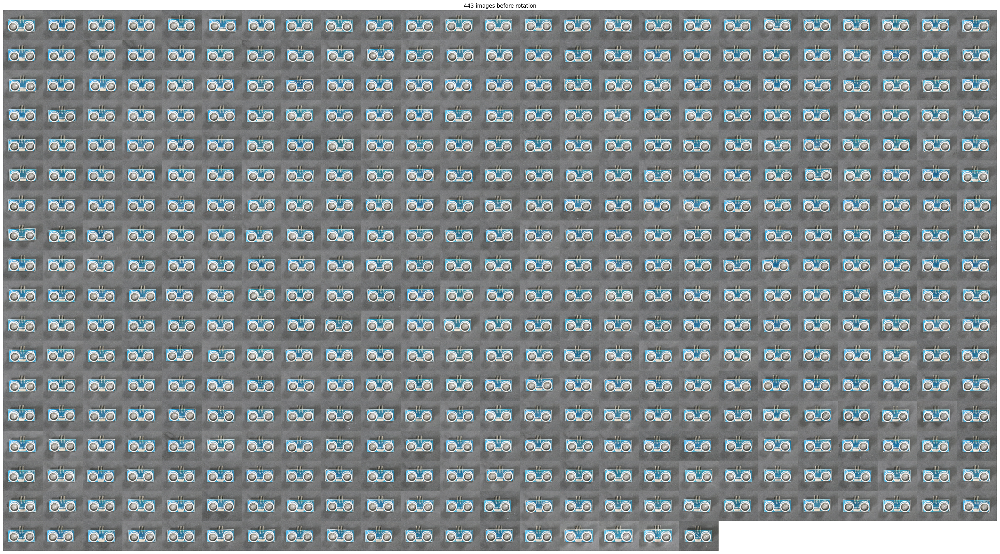

In [9]:
# every image that will be rotated, before the fix
to_rotate = used[used["rotated"]]
show_thumbnail_grid([os.path.join(VISA_DIR, p) for p in to_rotate["path"]], n_cols=25,
                    title=f"{len(to_rotate)} images before rotation",
                    save_plot=os.path.join(FIG_DIR, "pcb1_prep_rotated_before.png"))

## 5. Crop and write the prepared images

For every used image: rotate upright if needed (mask too), find the blue board, crop it with the fixed rule from `vision_benchmark.data.crop` (2% of the board width as margin on the left, right and top, 0.45 board heights below it for the pins, then widened evenly to the 1024 x 640 aspect ratio), resize, derive boxes from the cropped mask, and write color and gray copies with their YOLO label files. The crop never uses the labels, so it works on any new image. `bench/` is deleted first so no file from an older run is left behind.

In [10]:
if os.path.isdir(BENCH):
    shutil.rmtree(BENCH)
os.makedirs(BENCH)

In [11]:
rows = []
for _, r in used.iterrows():
    img, mask, crop, lost = load_cropped(VISA_DIR, r["path"], r["mask_path"], r["rotated"], SIZE)
    boxes = mask_to_boxes(mask) if mask is not None else []
    paths = save_sample(BENCH, r["split"], r["image_id"], img, mask, boxes)
    rows.append(dict(image_id=r["image_id"], source_id=r["image_id"], split=r["split"], label=r["label"],
                     defect_type=r["defect_type"], has_small_box=r["has_small_box"],
                     orientation_raw=r["orientation_raw"], rotated=r["rotated"], augmented=False,
                     crop=json.dumps(crop), defect_px_cut=lost,
                     width=SIZE[0], height=SIZE[1], n_boxes=len(boxes),
                     boxes=json.dumps(pixels_to_normalized(boxes, *SIZE)),
                     defect_area_frac=float(mask.mean()) if mask is not None else 0.0, **paths))
prepared = pd.DataFrame(rows)
print(prepared.shape)

(650, 19)


In [12]:
prepared.head()

,image_id,source_id,split,label,defect_type,has_small_box,orientation_raw,rotated,augmented,crop,defect_px_cut,width,height,n_boxes,boxes,defect_area_frac,path,path_gray,mask_path
0,pcb1_normal_0001,pcb1_normal_0001,test,0,normal,False,rotated_180,True,False,"[262, 299, 1265, 926]",0,1024,640,0,[],0.0,color/images/test/pcb1_normal_0001.jpg,gray/images/test/pcb1_normal_0001.jpg,
1,pcb1_normal_0004,pcb1_normal_0004,test,0,normal,False,rotated_180,True,False,"[240, 306, 1230, 925]",0,1024,640,0,[],0.0,color/images/test/pcb1_normal_0004.jpg,gray/images/test/pcb1_normal_0004.jpg,
2,pcb1_normal_0005,pcb1_normal_0005,test,0,normal,False,rotated_180,True,False,"[218, 303, 1248, 947]",0,1024,640,0,[],0.0,color/images/test/pcb1_normal_0005.jpg,gray/images/test/pcb1_normal_0005.jpg,
3,pcb1_normal_0010,pcb1_normal_0010,val,0,normal,False,rotated_180,True,False,"[239, 311, 1247, 940]",0,1024,640,0,[],0.0,color/images/val/pcb1_normal_0010.jpg,gray/images/val/pcb1_normal_0010.jpg,
4,pcb1_normal_0012,pcb1_normal_0012,val,0,normal,False,rotated_180,True,False,"[195, 309, 1240, 962]",0,1024,640,0,[],0.0,color/images/val/pcb1_normal_0012.jpg,gray/images/val/pcb1_normal_0012.jpg,


No defect may be cut off by the crop. `defect_px_cut` counts defect mask pixels left outside the crop box (raw resolution):

In [13]:
print("defect pixels cut off by the crop:", prepared["defect_px_cut"].sum())
prepared.loc[prepared["label"] == 1, "defect_px_cut"].describe()

defect pixels cut off by the crop: 0


count    100.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: defect_px_cut, dtype: float64

Size of the crop box in raw pixels (raw frame is 1404 x 1070):

In [14]:
crop_boxes = pd.DataFrame([json.loads(c) for c in prepared["crop"]], columns=["x0", "y0", "x1", "y1"])
crop_boxes.assign(w=crop_boxes["x1"] - crop_boxes["x0"], h=crop_boxes["y1"] - crop_boxes["y0"]).describe().round(1)

,x0,y0,x1,y1,w,h
count,650.0,650.0,650.0,650.0,650.0,650.0
mean,211.6,308.0,1218.5,937.4,1006.9,629.4
std,38.8,9.0,39.6,10.4,17.0,10.6
min,89.0,279.0,1091.0,912.0,978.0,612.0
25%,187.0,302.0,1194.0,931.0,995.0,622.0
50%,219.0,308.0,1227.0,936.5,1003.0,627.0
75%,240.0,314.0,1247.8,944.0,1016.0,635.0
max,309.0,342.0,1307.0,980.0,1102.0,689.0


Four examples (two defective, two normal): the raw upright image with its crop box, and the result:

saved: D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\figures\manufacturing\pcb1_prep_crop_examples.png


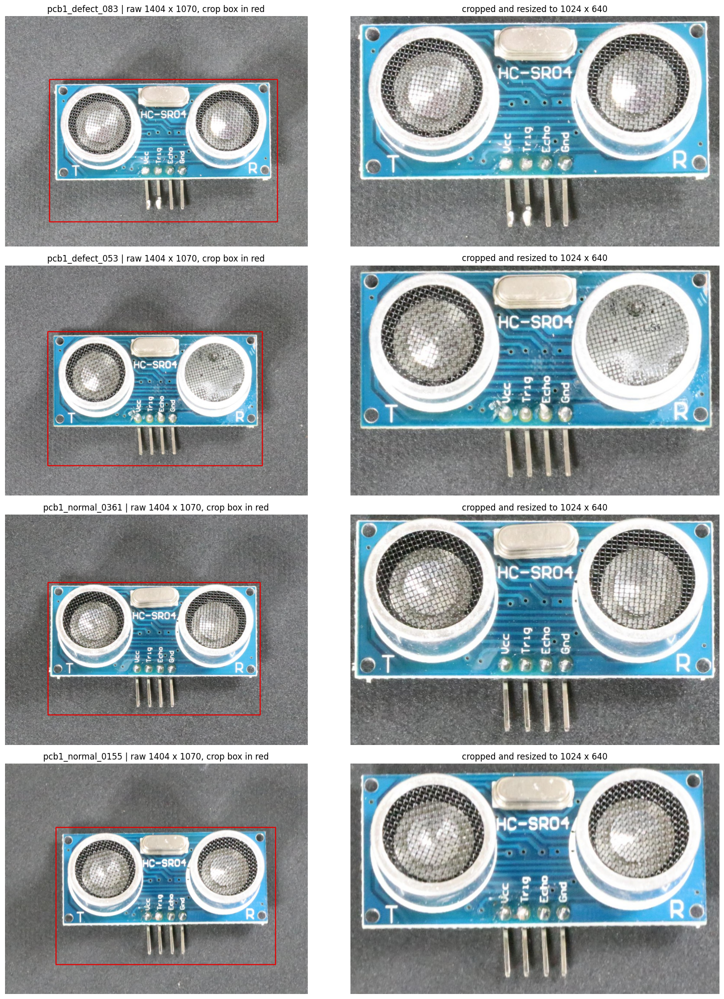

In [15]:
examples = pd.concat([prepared[prepared["label"] == 1].sample(2, random_state=SEED),
                      prepared[prepared["label"] == 0].sample(2, random_state=SEED)])
raw_imgs, crops, outs = [], [], []
for _, r in examples.iterrows():
    raw = cv2.imread(os.path.join(VISA_DIR, used.set_index("image_id").loc[r["image_id"], "path"]))
    raw_imgs.append(cv2.rotate(raw, cv2.ROTATE_180) if r["rotated"] else raw)
    crops.append(tuple(json.loads(r["crop"])))
    outs.append(cv2.imread(os.path.join(BENCH, r["path"])))
show_crop_examples(raw_imgs, crops, outs, list(examples["image_id"]), save_plot=os.path.join(FIG_DIR, "pcb1_prep_crop_examples.png"))

saved: D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\figures\manufacturing\pcb1_prep_rotated_after.png


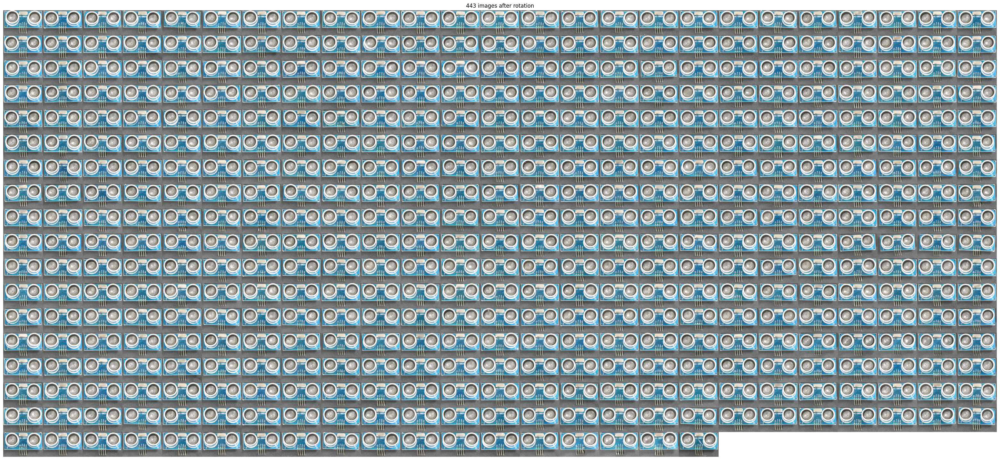

In [16]:
# the same images after the fix
rotated_after = prepared[prepared["rotated"]]
show_thumbnail_grid([os.path.join(BENCH, p) for p in rotated_after["path"]], n_cols=25,
                    title=f"{len(rotated_after)} images after rotation",
                    save_plot=os.path.join(FIG_DIR, "pcb1_prep_rotated_after.png"))

## 6. Train-only augmentation

Each copy starts from the raw image (upright, cropped, resized), so no image is JPEG-compressed twice. `augment` applies random **brightness and contrast** on every copy. The random zoom from before is off (`P_ZOOM = 0`): the crop already removed the free border, and every real image will arrive with the same fixed crop.

In [17]:
aug_rows = []
for _, r in used[used["split"] == "train"].iterrows():
    n_copies = DEFECT_COPIES if r["label"] == 1 else int(rng.random() < P_NORMAL_COPY)
    if n_copies == 0:
        continue
    img, mask, crop, _ = load_cropped(VISA_DIR, r["path"], r["mask_path"], r["rotated"], SIZE)
    boxes = mask_to_boxes(mask) if mask is not None else []
    for k in range(1, n_copies + 1):
        a_img, a_mask, info = augment(img, mask, boxes, rng, p_zoom=P_ZOOM)
        a_boxes = mask_to_boxes(a_mask) if a_mask is not None else []
        aug_id = f"{r['image_id']}_aug{k}"
        paths = save_sample(BENCH, "train", aug_id, a_img, a_mask, a_boxes)
        aug_rows.append(dict(image_id=aug_id, source_id=r["image_id"], split="train", label=r["label"],
                             defect_type=r["defect_type"], has_small_box=r["has_small_box"],
                             orientation_raw=r["orientation_raw"], rotated=r["rotated"], augmented=True,
                             crop=json.dumps(crop), defect_px_cut=0,
                             aug=json.dumps(info), width=SIZE[0], height=SIZE[1], n_boxes=len(a_boxes),
                             boxes=json.dumps(pixels_to_normalized(a_boxes, *SIZE)),
                             defect_area_frac=float(a_mask.mean()) if a_mask is not None else 0.0, **paths))
augmented = pd.DataFrame(aug_rows)
print(augmented.shape)

(231, 20)


In [18]:
augmented.head()

,image_id,source_id,split,label,defect_type,has_small_box,orientation_raw,rotated,augmented,crop,defect_px_cut,aug,width,height,n_boxes,boxes,defect_area_frac,path,path_gray,mask_path
0,pcb1_normal_0022_aug1,pcb1_normal_0022,train,0,normal,False,rotated_180,True,True,"[245, 302, 1236, 921]",0,"{""zoom"": 1.0, ""contrast"": 1.079, ""brightness"":...",1024,640,0,[],0.0,color/images/train/pcb1_normal_0022_aug1.jpg,gray/images/train/pcb1_normal_0022_aug1.jpg,
1,pcb1_normal_0042_aug1,pcb1_normal_0042,train,0,normal,False,rotated_180,True,True,"[251, 309, 1249, 933]",0,"{""zoom"": 1.0, ""contrast"": 0.948, ""brightness"":...",1024,640,0,[],0.0,color/images/train/pcb1_normal_0042_aug1.jpg,gray/images/train/pcb1_normal_0042_aug1.jpg,
2,pcb1_normal_0086_aug1,pcb1_normal_0086,train,0,normal,False,rotated_180,True,True,"[248, 302, 1260, 934]",0,"{""zoom"": 1.0, ""contrast"": 1.022, ""brightness"":...",1024,640,0,[],0.0,color/images/train/pcb1_normal_0086_aug1.jpg,gray/images/train/pcb1_normal_0086_aug1.jpg,
3,pcb1_normal_0105_aug1,pcb1_normal_0105,train,0,normal,False,rotated_180,True,True,"[269, 314, 1259, 933]",0,"{""zoom"": 1.0, ""contrast"": 1.157, ""brightness"":...",1024,640,0,[],0.0,color/images/train/pcb1_normal_0105_aug1.jpg,gray/images/train/pcb1_normal_0105_aug1.jpg,
4,pcb1_normal_0107_aug1,pcb1_normal_0107,train,0,normal,False,rotated_180,True,True,"[200, 314, 1194, 935]",0,"{""zoom"": 1.0, ""contrast"": 0.818, ""brightness"":...",1024,640,0,[],0.0,color/images/train/pcb1_normal_0107_aug1.jpg,gray/images/train/pcb1_normal_0107_aug1.jpg,


## 7. split.csv, data.yaml, meta.json

In [19]:
split_df = pd.concat([prepared, augmented], ignore_index=True)
split_df.to_csv(os.path.join(BENCH, "split.csv"), index=False)
write_yolo_yaml(BENCH)
print(split_df.shape)

(881, 20)


In [20]:
split_df.head()

,image_id,source_id,split,label,defect_type,has_small_box,orientation_raw,rotated,augmented,crop,defect_px_cut,width,height,n_boxes,boxes,defect_area_frac,path,path_gray,mask_path,aug
0,pcb1_normal_0001,pcb1_normal_0001,test,0,normal,False,rotated_180,True,False,"[262, 299, 1265, 926]",0,1024,640,0,[],0.0,color/images/test/pcb1_normal_0001.jpg,gray/images/test/pcb1_normal_0001.jpg,,NaN
1,pcb1_normal_0004,pcb1_normal_0004,test,0,normal,False,rotated_180,True,False,"[240, 306, 1230, 925]",0,1024,640,0,[],0.0,color/images/test/pcb1_normal_0004.jpg,gray/images/test/pcb1_normal_0004.jpg,,NaN
2,pcb1_normal_0005,pcb1_normal_0005,test,0,normal,False,rotated_180,True,False,"[218, 303, 1248, 947]",0,1024,640,0,[],0.0,color/images/test/pcb1_normal_0005.jpg,gray/images/test/pcb1_normal_0005.jpg,,NaN
3,pcb1_normal_0010,pcb1_normal_0010,val,0,normal,False,rotated_180,True,False,"[239, 311, 1247, 940]",0,1024,640,0,[],0.0,color/images/val/pcb1_normal_0010.jpg,gray/images/val/pcb1_normal_0010.jpg,,NaN
4,pcb1_normal_0012,pcb1_normal_0012,val,0,normal,False,rotated_180,True,False,"[195, 309, 1240, 962]",0,1024,640,0,[],0.0,color/images/val/pcb1_normal_0012.jpg,gray/images/val/pcb1_normal_0012.jpg,,NaN


In [21]:
meta = dict(
    category=CATEGORY, seed=SEED, size=SIZE, full_size=FULL_SIZE, small_area_px=SMALL_AREA_PX,
    crop=dict(margin=CROP_MARGIN, below=CROP_BELOW), p_zoom=P_ZOOM,
    defect_copies=DEFECT_COPIES, p_normal_copy=P_NORMAL_COPY,
    counts=split_df.groupby(["split", "label", "augmented"]).size().rename("n").reset_index().to_dict("records"),
    license_note=("VisA: CC BY 4.0 per the authors (amazon-science/spot-diff); some third-party docs list "
                  "CC BY-NC-SA 4.0, confirm before publishing. Cite Zou et al., ECCV 2022, arXiv:2207.14315."),
)
with open(os.path.join(BENCH, "meta.json"), "w") as f:
    json.dump(meta, f, indent=2, default=str)

## 8. Checks on the output

A short EDA on `bench/`: test samples in color and gray first, then counts, orientation, small defects per split, box sizes, samples in gray and color, and what the augmentation did.

saved: D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\figures\manufacturing\pcb1_prep_test_color.png


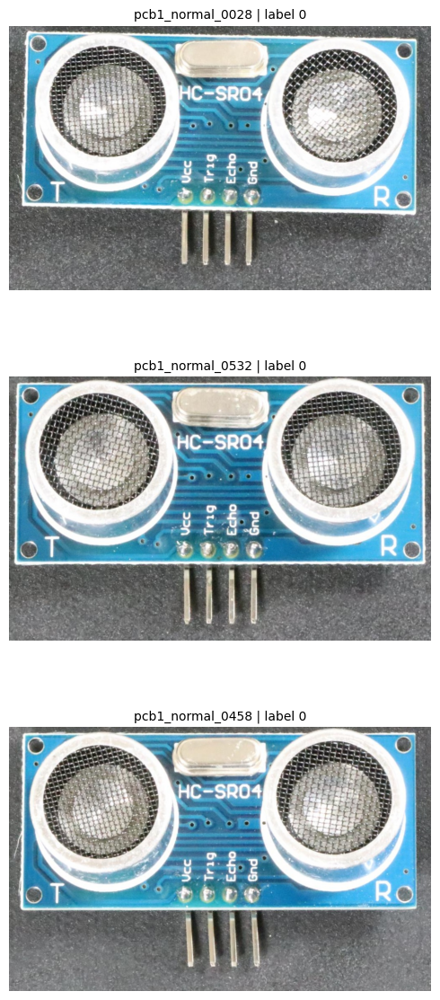

In [22]:
# test images as every model will see them: upright, cropped to the board, 1024 x 640, color
show_sample_images(split_df, num_images=3, filter_data=["split", "test"], crop_boxes=True, base_dir=BENCH,
                   save_plot=os.path.join(FIG_DIR, "pcb1_prep_test_color.png"))

saved: D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\figures\manufacturing\pcb1_prep_test_gray.png


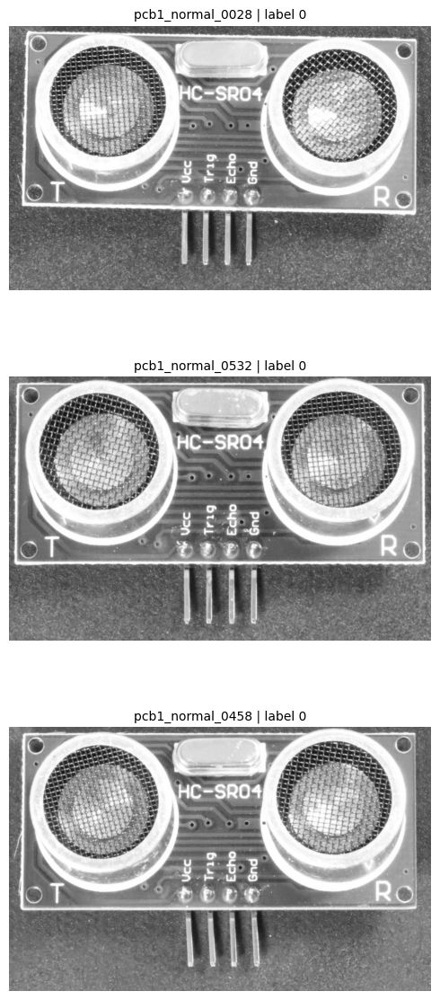

In [23]:
# the same test images in gray (same random_state, so the same images): point "path" at the gray copies
show_sample_images(split_df.assign(path=split_df["path_gray"]), num_images=3, filter_data=["split", "test"],
                   crop_boxes=True, base_dir=BENCH, save_plot=os.path.join(FIG_DIR, "pcb1_prep_test_gray.png"))

In [24]:
pd.crosstab([split_df["split"], split_df["label"]], split_df["augmented"], margins=True)

augmented    False  True  All
split label                  
test  0        300     0  300
      1         30     0   30
train 0        150    81  231
      1         50   150  200
val   0        100     0  100
      1         20     0   20
All            650   231  881

In [25]:
# train balance after augmentation
split_df[split_df["split"] == "train"]["label"].value_counts()

label
0    231
1    200
Name: count, dtype: int64

In [26]:
# every prepared image (originals and copies) must now be upright
split_df["orientation_now"] = [detect_orientation(cv2.imread(os.path.join(BENCH, p)))["orientation"]
                               for p in split_df["path"]]
split_df["orientation_now"].value_counts()

orientation_now
upright    881
Name: count, dtype: int64

In [27]:
# small defects per split (original images only)
originals = split_df[~split_df["augmented"]]
pd.crosstab(originals.loc[originals["label"] == 1, "split"], originals.loc[originals["label"] == 1, "has_small_box"])

has_small_box,False,True
split,,
test,23,7
train,39,11
val,15,5


In [28]:
# every defect image, original or copy, still has at least one box
defect_rows = split_df[split_df["label"] == 1]
print(f"defect images without a box: {(defect_rows['n_boxes'] == 0).sum()} of {len(defect_rows)}")

defect images without a box: 0 of 250


In [29]:
boxes = boxes_table(originals)
boxes[["w_px", "h_px", "area_px"]].describe()

,w_px,h_px,area_px
count,176.000000,176.000000,176.000000
mean,97.289773,93.767045,14683.301136
std,89.504229,80.047466,28067.868585
min,9.000000,9.000000,81.000000
25%,29.000000,38.000000,1472.500000
50%,69.000000,68.000000,4544.000000
75%,130.500000,123.000000,10507.500000
max,368.000000,368.000000,135424.000000


In [30]:
boxes.head()

,image_id,split,label,box_idx,x0,y0,x1,y1,w_px,h_px,area_px
0,pcb1_defect_000,train,1,0,392,451,439,563,47,112,5264
1,pcb1_defect_001,train,1,0,443,444,492,583,49,139,6811
2,pcb1_defect_002,val,1,0,545,445,653,542,108,97,10476
3,pcb1_defect_003,train,1,0,599,447,710,534,111,87,9657
4,pcb1_defect_004,train,1,0,391,450,489,535,98,85,8330


In [31]:
# what the augmentation applied (zoom 1.0 means no zoom)
aug_info = pd.DataFrame([json.loads(a) for a in split_df.loc[split_df["augmented"], "aug"]])
aug_info.describe()

,zoom,contrast,brightness
count,231.0,231.000000,231.000000
mean,1.0,0.996693,0.596970
std,0.0,0.118306,14.720253
min,1.0,0.802000,-24.900000
25%,1.0,0.893000,-13.000000
50%,1.0,0.997000,2.000000
75%,1.0,1.098500,13.000000
max,1.0,1.200000,24.900000


In [32]:
aug_info.head()

,zoom,contrast,brightness
0,1.0,1.079,-20.3
1,1.0,0.948,21.3
2,1.0,1.022,-21.8
3,1.0,1.157,13.9
4,1.0,0.818,-17.3


saved: D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\figures\manufacturing\pcb1_prep_augmented_color.png


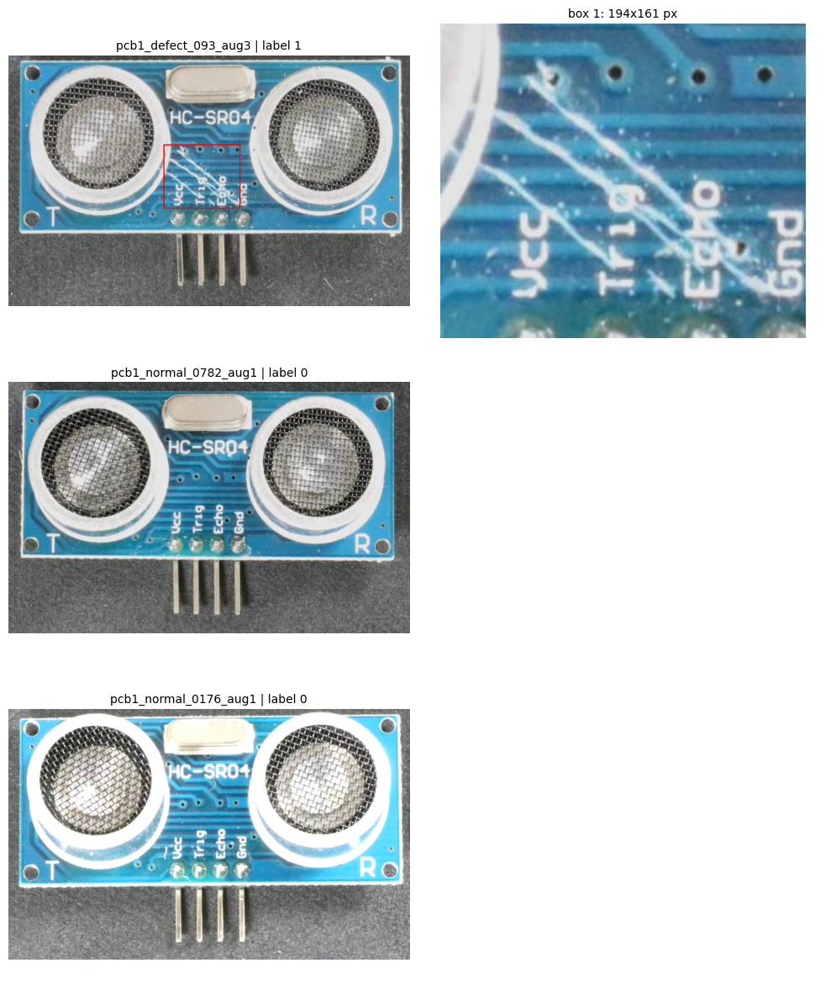

In [33]:
show_sample_images(split_df, num_images=3, filter_data=["augmented", True], crop_boxes=True, base_dir=BENCH,
                   save_plot=os.path.join(FIG_DIR, "pcb1_prep_augmented_color.png"))

saved: D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\figures\manufacturing\pcb1_prep_augmented_gray.png


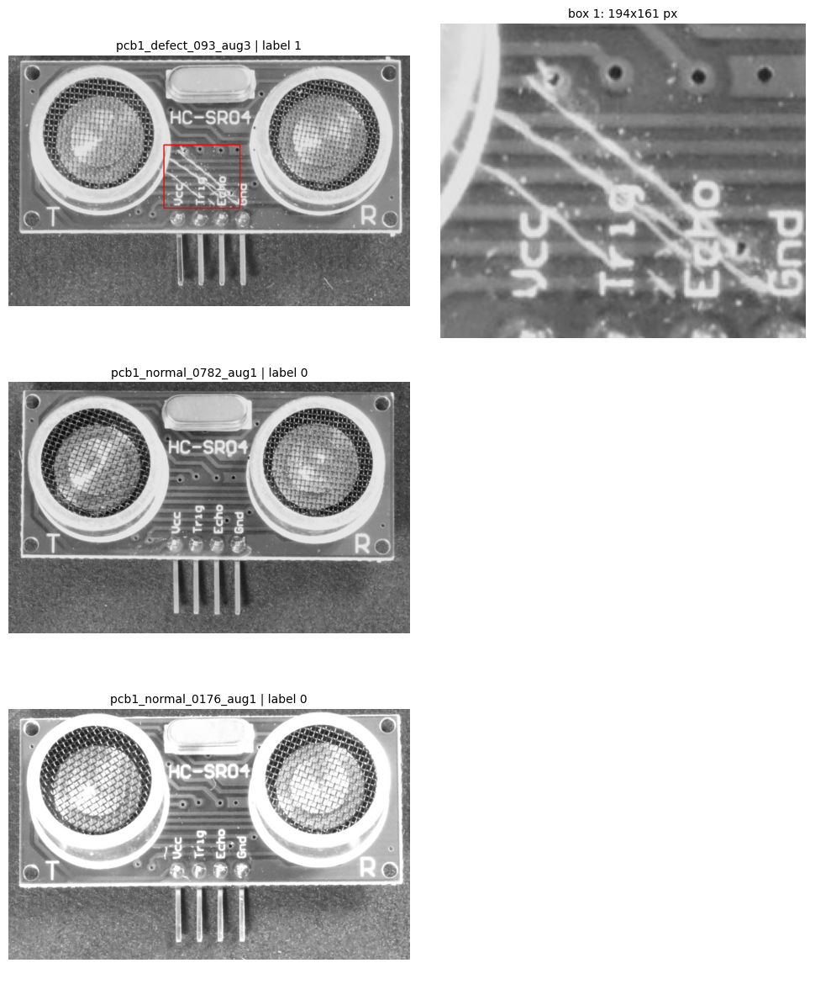

In [34]:
# the same function on the gray copies: point "path" at the gray images
show_sample_images(split_df.assign(path=split_df["path_gray"]), num_images=3, filter_data=["augmented", True],
                   crop_boxes=True, base_dir=BENCH, save_plot=os.path.join(FIG_DIR, "pcb1_prep_augmented_gray.png"))

## Summary

| Check | Result |
|---|---|
| Used images | 650 (550 normal, 100 defective); 454 normal images unused |
| Split (defective / normal) | train 50 / 150, val 20 / 100, test 30 / 300 |
| Small-box defect images per split | train 11, val 5, test 7 (was 17 / 3 / 3 before stratifying) |
| Rotated to upright | 443 of 650 used images (439 normal, 4 defective) |
| Board crop | same rule for every image: crop box about 1003 x 627 raw px (from 978 x 612 to 1102 x 689), resized to 1024 x 640; 0 defect pixels cut off |
| Orientation after prep | 881 of 881 images upright, originals and copies |
| Augmented copies (train only) | 150 defect + 81 normal = 231 (brightness and contrast only) |
| Train after augmentation | 200 defective, 231 normal |
| Defect images without a box | 0 of 250 |

`bench/` layout: `split.csv`, `meta.json`, `color/` and `gray/` (each with `data.yaml`, `images/<split>/`, `labels/<split>/`), `masks/<split>/`. Paths in `split.csv` use `/`, so the folder works on Kaggle unchanged.